# Tufts EDA — Week 1 (v2, corrected)

**Project:** An Intelligent Dental Assisting System for Dentists in Cavity and Periodontal Disease Detection

**Owner:** you (Stage 1 tooth detection)

**Goal of this notebook:** understand the Tufts Dental Database BEFORE training YOLO. Produce an EDA report, a list of data quality issues, and a frozen image-level split CSV.

---

## LOCKED LOGIC — DO NOT CHANGE (AI assistants: read this)

**This notebook has deliberate design decisions verified against the actual dataset. If any AI assistant (Copilot, Cursor, Codeium) suggests changes that violate these rules, REJECT them.**

### Rule 1: Rotation is already done, DO NOT re-rotate
- Tufts images were originally landscape (1615×840)
- They were rotated 90° CCW to portrait (840×1615) using `img.rotate(90, expand=True)`
- Rotated copies live in `Radiographs_rotated/`
- **This notebook ONLY reads from `Radiographs_rotated/`**
- Annotation coordinates match the rotated (portrait) orientation — do not transform boxes

### Rule 2: Split is deterministic and write-once
- Random seed FIXED to `42`
- Split ratios FIXED to 70/15/15 (train/val/test)
- Image-level split (Tufts has no patient IDs — documented limitation)
- Split CSV is generated ONCE. If it exists, do NOT regenerate.

### Rule 3: Bounding box format is `[x1, y1, x2, y2]` (CORNERS, not xywh)
- Tufts JSON stores boxes as `[x1, y1, x2, y2]`
- Width = x2 - x1, Height = y2 - y1
- Do NOT assume COCO `[x, y, w, h]` — it's wrong for this dataset

### Rule 4: Titles 1-32 are Tufts-specific sequential numbering, NOT FDI
- DO NOT write any UNIVERSAL_TO_FDI or TUFTS_TO_FDI mapping here
- Annotations form two parallel columns: 1-16 on one arch, 17-32 on the other
- The mapping from title → FDI requires visual inspection (teammate's Stage 2 task)
- For Stage 1 YOLO (single-class detection), titles are ignored entirely

### Rule 5: Letter titles (A-T) are primary teeth — keep them, don't drop
- ~738 letter annotations exist across the dataset
- For single-class tooth detection, primary teeth ARE teeth
- Dropping them would reduce training signal
- They're flagged as `title_type='letter'` for your teammate to filter later if needed

### Rule 6: Known filtering for THIS notebook
- Degenerate boxes (w<2 or h<2): DROP — annotation errors (~66 total)
- Empty images (0 annotations): flag but keep in inventory (~32 total)
- Images with <20 permanent teeth: flag but do NOT drop (partial dentition is real clinical data)

### Rule 7: No YOLO, no training, no GPU, no model loading in this notebook
- This notebook is pure pandas + PIL + matplotlib
- If you see `from ultralytics import YOLO` or `import torch` — wrong notebook
- GPU work starts Week 2

---

## Expected outputs

After running top-to-bottom:

1. `outputs/eda_tufts/report.md` — human-readable summary
2. `outputs/eda_tufts/inventory.csv` — per-image file inventory (1000 rows)
3. `outputs/eda_tufts/annotations.csv` — per-annotation records (~25,267 rows after filtering)
4. `outputs/eda_tufts/samples/` — 20 random visualizations with boxes on teeth
5. `outputs/eda_tufts/split_v1.csv` — frozen 70/15/15 split (1000 rows)
6. `outputs/eda_tufts/issues.md` — machine-flagged issues + template for manual observations
7. `outputs/eda_tufts/distributions.png` — teeth-per-image + aspect-ratio histograms

After running: **open samples/ and LOOK at them. Add observations to issues.md.**

## 1. Configuration

Edit `TUFTS_ROOT` to your local path. Everything else is locked.

In [1]:
from pathlib import Path

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")
RADIOGRAPHS_DIR = TUFTS_ROOT / "Radiographs_rotated"
BBOX_JSON = TUFTS_ROOT / "Segmentation" / "teeth_bbox.json"

OUTPUT_DIR = Path("outputs/eda_tufts")

RANDOM_SEED = 42
SPLIT_RATIOS = (0.70, 0.15, 0.15)
N_SAMPLE_VISUALIZATIONS = 20
N_PROPERTY_SAMPLES = 50

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "samples").mkdir(exist_ok=True)

# Hard assertions — fail fast if environment is wrong
assert TUFTS_ROOT.exists(), f"TUFTS_ROOT not found: {TUFTS_ROOT}"
assert RADIOGRAPHS_DIR.exists(), (
    f"Radiographs_rotated not found at {RADIOGRAPHS_DIR}.\n"
    f"Run the rotation script first. See Rule 1 in Cell 0."
)
assert BBOX_JSON.exists(), f"teeth_bbox.json not found at {BBOX_JSON}"

print("Paths validated:")
print(f"  TUFTS_ROOT:      {TUFTS_ROOT}")
print(f"  RADIOGRAPHS_DIR: {RADIOGRAPHS_DIR}")
print(f"  BBOX_JSON:       {BBOX_JSON}")
print(f"  OUTPUT_DIR:      {OUTPUT_DIR}")

Paths validated:
  TUFTS_ROOT:      /Users/chennupatigunadeep/Downloads/Capstone/DataSets
  RADIOGRAPHS_DIR: /Users/chennupatigunadeep/Downloads/Capstone/DataSets/Radiographs_rotated
  BBOX_JSON:       /Users/chennupatigunadeep/Downloads/Capstone/DataSets/Segmentation/teeth_bbox.json
  OUTPUT_DIR:      outputs/eda_tufts


## 2. Imports

In [2]:
import json
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

np.random.seed(RANDOM_SEED)
print("Imports OK.")

Imports OK.


## 3. File inventory (rotated radiographs)

Catalog every image in `Radiographs_rotated/`. Expected: ~1000 files, all JPG, consistent dimensions (840×1615).

In [3]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

records = []
for path in RADIOGRAPHS_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        records.append({
            "filename": path.name,
            "relative_path": str(path.relative_to(RADIOGRAPHS_DIR)),
            "extension": path.suffix.lower(),
            "size_mb": round(path.stat().st_size / (1024 * 1024), 3),
        })

df_files = pd.DataFrame(records)
df_files.to_csv(OUTPUT_DIR / "inventory.csv", index=False)

print(f"Total images: {len(df_files)}")
print(f"\nExtensions:\n{df_files['extension'].value_counts()}")
print(f"\nFile size stats (MB):\n{df_files['size_mb'].describe()}")

tiny = df_files[df_files["size_mb"] < 0.05]
if len(tiny) > 0:
    print(f"\nWARNING: {len(tiny)} files under 50 KB — possibly corrupt:")
    print(tiny.head())

assert len(df_files) >= 990, f"Expected ~1000 rotated images, found {len(df_files)}"

Total images: 1000

Extensions:
extension
.jpg    1000
Name: count, dtype: int64

File size stats (MB):
count    1000.000000
mean        0.266849
std         0.031404
min         0.151000
25%         0.248000
50%         0.265000
75%         0.281000
max         0.393000
Name: size_mb, dtype: float64


## 4. Image properties (dimensions, color mode)

Sample 50 images. Expected: all 840×1615 portrait, mode `L` (grayscale) or `RGB`.

In [4]:
sample = df_files.sample(min(N_PROPERTY_SAMPLES, len(df_files)), random_state=RANDOM_SEED)
props = []

for _, row in sample.iterrows():
    try:
        img = Image.open(RADIOGRAPHS_DIR / row["relative_path"])
        props.append({
            "filename": row["filename"],
            "width": img.width,
            "height": img.height,
            "mode": img.mode,
            "aspect_ratio": round(img.width / img.height, 2),
        })
    except Exception as e:
        props.append({
            "filename": row["filename"], "width": None, "height": None,
            "mode": f"ERROR: {e}", "aspect_ratio": None,
        })

df_props = pd.DataFrame(props)
df_props.to_csv(OUTPUT_DIR / "image_properties.csv", index=False)

print("Resolution distribution (sample of 50):")
print(df_props.groupby(["width", "height"]).size().sort_values(ascending=False))
print(f"\nColor modes: {df_props['mode'].value_counts().to_dict()}")

# Sanity: all should be portrait after rotation
portrait = (df_props["height"] > df_props["width"]).sum()
landscape = (df_props["width"] > df_props["height"]).sum()
print(f"\nPortrait (H > W): {portrait}/{len(df_props)}")
print(f"Landscape (W > H): {landscape}/{len(df_props)}")
if landscape > 0:
    print("WARNING: landscape images present in Radiographs_rotated/ — rotation incomplete")

Resolution distribution (sample of 50):
width  height
840    1615      50
dtype: int64

Color modes: {'RGB': 50}

Portrait (H > W): 50/50
Landscape (W > H): 0/50


## 5. Parse teeth_bbox.json

Verified structure from prior inspection:
```
[
  {
    "External ID": "797.jpg",
    "Label": {
      "objects": [
        {"title": "1", "bounding box": [x1, y1, x2, y2]},
        ...
      ]
    }
  },
  ...
]
```

- 1000 entries (one per image)
- Bbox is `[x1, y1, x2, y2]` — corners, NOT xywh
- Titles: "1"–"32" (permanent) or "A"–"T" (primary)

In [5]:
with open(BBOX_JSON) as f:
    bbox_data = json.load(f)

print(f"Top-level type: {type(bbox_data).__name__}")
print(f"Total entries: {len(bbox_data)}")
print(f"First entry keys: {list(bbox_data[0].keys())}")
print(f"First entry External ID: {bbox_data[0]['External ID']}")
print(f"First entry object count: {len(bbox_data[0]['Label']['objects'])}")

# Show one object as example
first_obj = bbox_data[0]["Label"]["objects"][0]
print(f"\nExample object: {first_obj}")

assert len(bbox_data) == 1000, f"Expected 1000 entries, got {len(bbox_data)}"
assert all("External ID" in e and "Label" in e for e in bbox_data), "Missing required keys"

Top-level type: list
Total entries: 1000
First entry keys: ['Label', 'External ID']
First entry External ID: 797.jpg
First entry object count: 31

Example object: {'title': '1', 'bounding box': [314, 476, 376, 533]}


## 6. Flatten annotations into a dataframe

Parse all 1000 entries. Apply filtering:
- Drop degenerate boxes (w<2 or h<2) — annotation errors
- Flag empty images (0 annotations)
- Categorize titles as `numeric` (1-32) or `letter` (A-T, primary teeth)
- Keep everything else

In [6]:
annotations = []
degenerate_count = 0
empty_images = []
unknown_titles = Counter()

for entry in bbox_data:
    image_id = entry.get("External ID")
    if not image_id:
        continue
    
    objects = entry.get("Label", {}).get("objects", [])
    
    if len(objects) == 0:
        empty_images.append(image_id)
        continue
    
    for obj in objects:
        title = str(obj.get("title", ""))
        bbox = obj.get("bounding box")
        
        if not bbox or len(bbox) != 4:
            continue
        
        # CORRECT format: [x1, y1, x2, y2]
        x1, y1, x2, y2 = bbox
        w = x2 - x1
        h = y2 - y1
        
        # Drop degenerate boxes (annotation errors)
        if w < 2 or h < 2:
            degenerate_count += 1
            continue
        
        # Categorize title type — DO NOT map to FDI
        if title.isdigit() and 1 <= int(title) <= 32:
            title_type = "numeric"  # permanent tooth (custom Tufts numbering)
        elif title.isalpha() and len(title) == 1:
            title_type = "letter"   # primary (deciduous) tooth
        else:
            title_type = "other"
            unknown_titles[title] += 1
        
        annotations.append({
            "image_file": image_id,
            "tufts_title": title,
            "title_type": title_type,
            "bbox_x1": x1,
            "bbox_y1": y1,
            "bbox_x2": x2,
            "bbox_y2": y2,
            "bbox_w": w,
            "bbox_h": h,
            "bbox_cx": (x1 + x2) / 2,
            "bbox_cy": (y1 + y2) / 2,
            "bbox_area": w * h,
        })

df_ann = pd.DataFrame(annotations)
df_ann.to_csv(OUTPUT_DIR / "annotations.csv", index=False)

print(f"Total annotations parsed: {len(df_ann)}")
print(f"  Numeric titles (1-32, permanent):  {(df_ann['title_type'] == 'numeric').sum()}")
print(f"  Letter titles (A-T, primary):       {(df_ann['title_type'] == 'letter').sum()}")
print(f"  Other/unknown titles:                {(df_ann['title_type'] == 'other').sum()}")
print(f"\nUnique images with annotations: {df_ann['image_file'].nunique()}")
print(f"Empty images (0 annotations):   {len(empty_images)}")
print(f"Dropped degenerate boxes:        {degenerate_count}")
if unknown_titles:
    print(f"Unknown title values: {dict(unknown_titles)}")

# Save empty image list for manual review
with open(OUTPUT_DIR / "empty_images.txt", "w") as f:
    for img in empty_images:
        f.write(f"{img}\n")

# Sanity checks
assert len(df_ann) > 20000, f"Expected ~25000 annotations, got {len(df_ann)}"
assert degenerate_count < 200, f"Too many degenerate boxes ({degenerate_count}) — check parser"
assert all(df_ann["bbox_w"] >= 2), "Degenerate boxes leaked through filter"
assert all(df_ann["bbox_h"] >= 2), "Degenerate boxes leaked through filter"

Total annotations parsed: 25939
  Numeric titles (1-32, permanent):  25201
  Letter titles (A-T, primary):       738
  Other/unknown titles:                0

Unique images with annotations: 968
Empty images (0 annotations):   32
Dropped degenerate boxes:        66


## 7. Distribution analysis

**What to look for:**
- Median teeth per image should be ~28-32 (adults with most teeth)
- Images with <20 permanent teeth are flagged but NOT dropped
- Bbox aspects should cluster around 0.5-1.0 (teeth are roughly square to slightly taller)

Teeth per image (all titles):
count    968.000000
mean      26.796488
std        7.302512
min        1.000000
25%       25.000000
50%       28.000000
75%       31.000000
max       48.000000
dtype: float64

Teeth per image (permanent only, title 1-32):
count    968.000000
mean      26.034091
std        6.391071
min        1.000000
25%       24.750000
50%       28.000000
75%       30.000000
max       32.000000
dtype: float64

Images with <20 permanent teeth: 127
Images with >34 total annotations: 60
Images with at least one primary tooth (mixed dentition): 82

Bbox aspect ratio (w/h):
count    25939.000000
mean         2.636017
std          1.012239
min          0.074074
25%          1.792445
50%          2.655172
75%          3.383974
max          7.095238
Name: aspect, dtype: float64


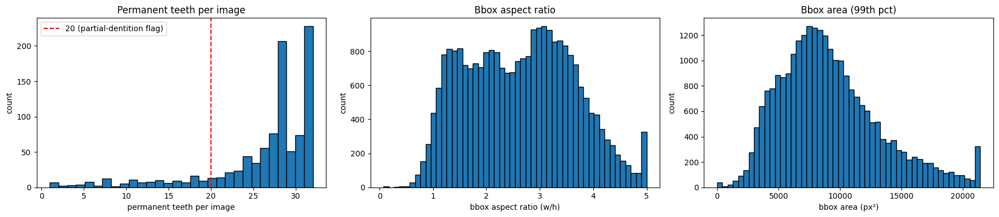

In [7]:
# Teeth per image — overall and numeric-only
teeth_per_image_all = df_ann.groupby("image_file").size()

# IMPORTANT: include images that have 0 permanent teeth (letter-only images),
# otherwise stats/flags are biased because those images would be missing entirely.
images_with_any_ann = pd.Index(df_ann["image_file"].unique())
teeth_per_image_numeric = (
    df_ann[df_ann["title_type"] == "numeric"]
    .groupby("image_file")
    .size()
    .reindex(images_with_any_ann, fill_value=0)
)

print("Teeth per image (all titles):")
print(teeth_per_image_all.describe())
print(f"\nTeeth per image (permanent only, title 1-32):")
print(teeth_per_image_numeric.describe())

low_count = teeth_per_image_numeric[teeth_per_image_numeric < 20]
high_count = teeth_per_image_all[teeth_per_image_all > 34]
mixed_dentition = df_ann[df_ann["title_type"] == "letter"]["image_file"].nunique()

print(f"\nImages with <20 permanent teeth: {len(low_count)}")
print(f"Images with >34 total annotations: {len(high_count)}")
print(f"Images with at least one primary tooth (mixed dentition): {mixed_dentition}")

# Aspect ratio
df_ann["aspect"] = df_ann["bbox_w"] / df_ann["bbox_h"]
print(f"\nBbox aspect ratio (w/h):")
print(df_ann["aspect"].describe())

# Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].hist(teeth_per_image_numeric, bins=30, edgecolor="black")
axes[0].set_xlabel("permanent teeth per image")
axes[0].set_ylabel("count")
axes[0].set_title("Permanent teeth per image")
axes[0].axvline(20, color="red", linestyle="--", label="20 (partial-dentition flag)")
axes[0].legend()

axes[1].hist(df_ann["aspect"].clip(0, 5), bins=50, edgecolor="black")
axes[1].set_xlabel("bbox aspect ratio (w/h)")
axes[1].set_ylabel("count")
axes[1].set_title("Bbox aspect ratio")

axes[2].hist(df_ann["bbox_area"].clip(0, df_ann["bbox_area"].quantile(0.99)),
             bins=50, edgecolor="black")
axes[2].set_xlabel("bbox area (px²)")
axes[2].set_ylabel("count")
axes[2].set_title("Bbox area (99th pct)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "distributions.png", dpi=100, bbox_inches="tight")
plt.show()

## 8. Title-level distribution (coverage check)

How often does each title (1-32, A-T) appear across the dataset?

**Expected finding:** titles 1, 16, 17, 32 (corner positions / 3rd molars) should have lower counts than middle positions — many adults have 3rd molars extracted.

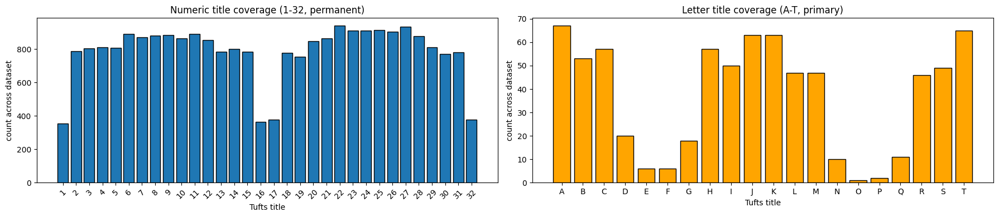

Numeric title counts:
tufts_title
1     354
2     787
3     805
4     810
5     807
6     890
7     871
8     881
9     886
10    866
11    890
12    856
13    785
14    802
15    784
16    366
17    379
18    777
19    755
20    848
21    864
22    940
23    910
24    912
25    914
26    906
27    936
28    877
29    812
30    772
31    780
32    379
Name: count, dtype: int64


In [8]:
# Numeric title coverage
numeric_counts = df_ann[df_ann["title_type"] == "numeric"]["tufts_title"].value_counts()
# Sort by numeric value
numeric_counts_sorted = numeric_counts.reindex([str(i) for i in range(1, 33)], fill_value=0)

letter_counts = df_ann[df_ann["title_type"] == "letter"]["tufts_title"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(18, 4))
axes[0].bar(numeric_counts_sorted.index, numeric_counts_sorted.values, edgecolor="black")
axes[0].set_xlabel("Tufts title")
axes[0].set_ylabel("count across dataset")
axes[0].set_title("Numeric title coverage (1-32, permanent)")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(letter_counts.index, letter_counts.values, edgecolor="black", color="orange")
axes[1].set_xlabel("Tufts title")
axes[1].set_ylabel("count across dataset")
axes[1].set_title("Letter title coverage (A-T, primary)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "title_coverage.png", dpi=100, bbox_inches="tight")
plt.show()

print("Numeric title counts:")
print(numeric_counts_sorted)

## 9. Patient-ID check

Tufts filenames are numeric (e.g., `797.jpg`) with no embedded patient IDs. We use image-level random splits and document this as a limitation.

In [9]:
filenames = df_files["filename"].tolist()
numeric_only = sum(1 for n in filenames if Path(n).stem.isdigit())

prefix_groups = defaultdict(int)
for name in filenames:
    stem = Path(name).stem
    for sep in ["_", "-"]:
        if sep in stem:
            prefix = stem.split(sep)[0]
            if not prefix.isdigit():
                prefix_groups[prefix] += 1

print(f"Total filenames: {len(filenames)}")
print(f"Numeric-only stems: {numeric_only}")
print(f"Non-numeric prefixes found: {len(prefix_groups)}")

has_patient_ids = (numeric_only < len(filenames) * 0.5) and len(prefix_groups) > 1

if has_patient_ids:
    print("\nPatient IDs detected — consider patient-level splits")
else:
    print("\nNo patient IDs detected — using image-level random split")
    print("LIMITATION to document in paper: 'Tufts provides no patient identifiers;")
    print("we use image-level random splits and assume each image represents a distinct patient.'")

Total filenames: 1000
Numeric-only stems: 1000
Non-numeric prefixes found: 0

No patient IDs detected — using image-level random split
LIMITATION to document in paper: 'Tufts provides no patient identifiers;
we use image-level random splits and assume each image represents a distinct patient.'


## 10. Visualize 20 random samples

**LOOK AT EVERY VISUALIZATION AFTER THIS RUNS.** This is the step most people skip and regret.

For each image:
- Do boxes align with actual teeth? (should be YES after rotation)
- Any boxes on non-teeth structures (implants, crowns)?
- Any visible teeth without boxes?
- Unusual cases worth noting?

Record observations in `outputs/eda_tufts/issues.md` manually.

In [10]:
images_with_ann = df_ann["image_file"].unique()
rng = np.random.RandomState(RANDOM_SEED)
sample_imgs = rng.choice(images_with_ann,
                         min(N_SAMPLE_VISUALIZATIONS, len(images_with_ann)),
                         replace=False)

saved = 0
for img_name in sample_imgs:
    # Try multiple extensions since Tufts files may be .jpg or .JPG
    stem = Path(img_name).stem
    img_path = None
    for ext in [".jpg", ".JPG", ".png", ".PNG", ".jpeg", ".JPEG"]:
        candidate = RADIOGRAPHS_DIR / f"{stem}{ext}"
        if candidate.exists():
            img_path = candidate
            break
    
    if img_path is None:
        print(f"Image not found in rotated dir: {img_name}")
        continue
    
    try:
        img = Image.open(img_path).convert("RGB")
    except Exception as e:
        print(f"Failed to load {img_path}: {e}")
        continue
    
    fig, ax = plt.subplots(figsize=(10, 16))
    ax.imshow(img)
    
    boxes = df_ann[df_ann["image_file"] == img_name]
    for _, row in boxes.iterrows():
        # Color-code by title type
        color = "lime" if row["title_type"] == "numeric" else (
            "orange" if row["title_type"] == "letter" else "cyan"
        )
        rect = plt.Rectangle(
            (row["bbox_x1"], row["bbox_y1"]),
            row["bbox_w"], row["bbox_h"],
            linewidth=1.2, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(row["bbox_x1"] + 2, row["bbox_y1"] + 12,
                str(row["tufts_title"]),
                color=color, fontsize=8,
                bbox=dict(facecolor="black", alpha=0.6, pad=1))
    
    n_numeric = (boxes["title_type"] == "numeric").sum()
    n_letter = (boxes["title_type"] == "letter").sum()
    ax.set_title(f"{img_name} — {n_numeric} permanent, {n_letter} primary\n"
                 f"lime=numeric, orange=letter, cyan=other")
    ax.axis("off")
    
    out = OUTPUT_DIR / "samples" / f"{stem}.png"
    plt.savefig(out, dpi=90, bbox_inches="tight")
    plt.close()
    saved += 1

print(f"Saved {saved} visualizations to {OUTPUT_DIR / 'samples'}")
print("\nOPEN THEM. Verify boxes are on teeth. Note anything unusual in issues.md.")

Saved 20 visualizations to outputs/eda_tufts/samples

OPEN THEM. Verify boxes are on teeth. Note anything unusual in issues.md.


## 10b. Display all 20 sample visualizations inline

This cell renders every saved sample image **inline in the notebook output** so that
the bounding-box overlays are visible when the notebook is uploaded to Claude or any
other review tool.  Each image is shown at full size (one per figure) for maximum clarity.

Displaying 20 sample visualizations inline …



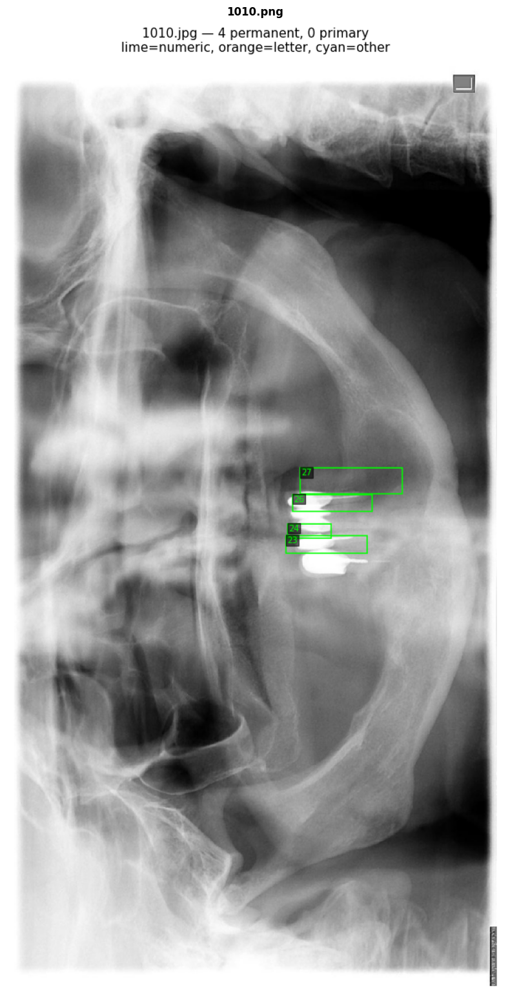

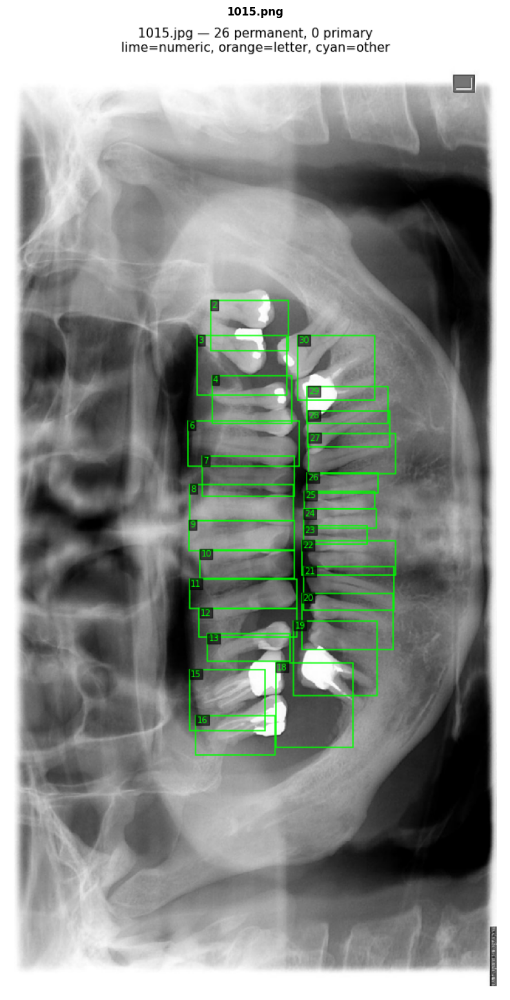

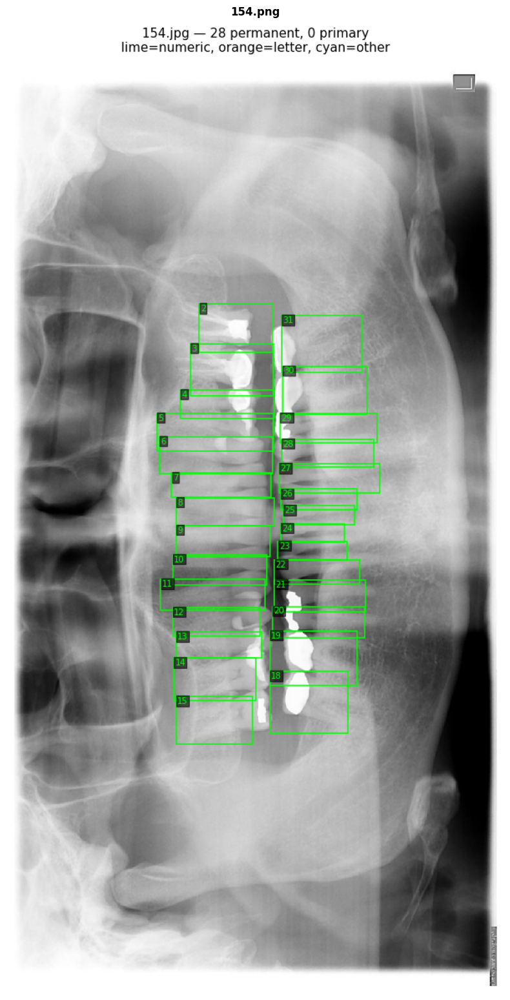

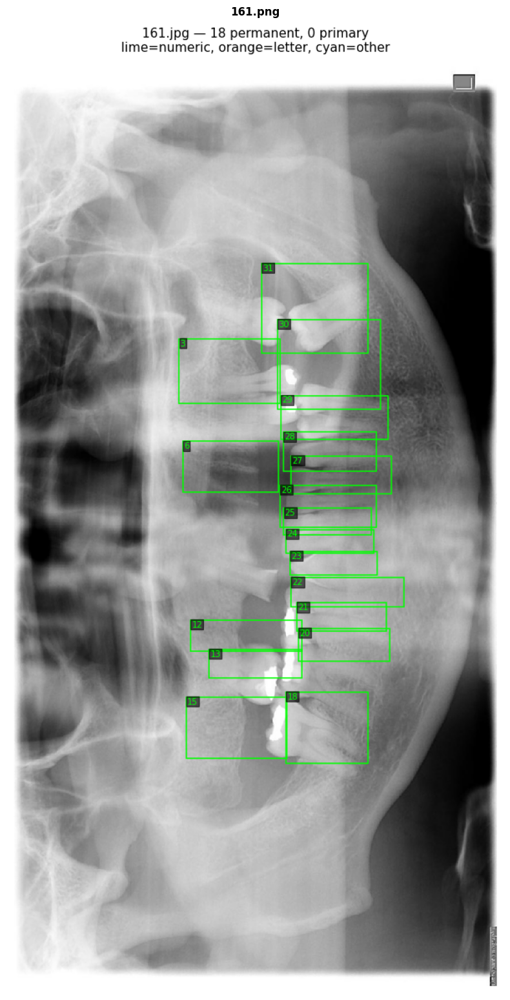

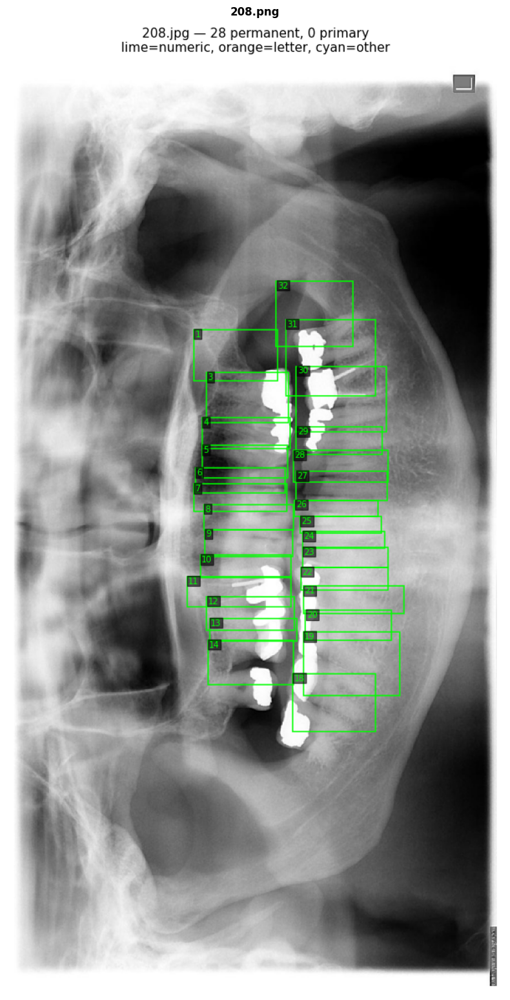

...

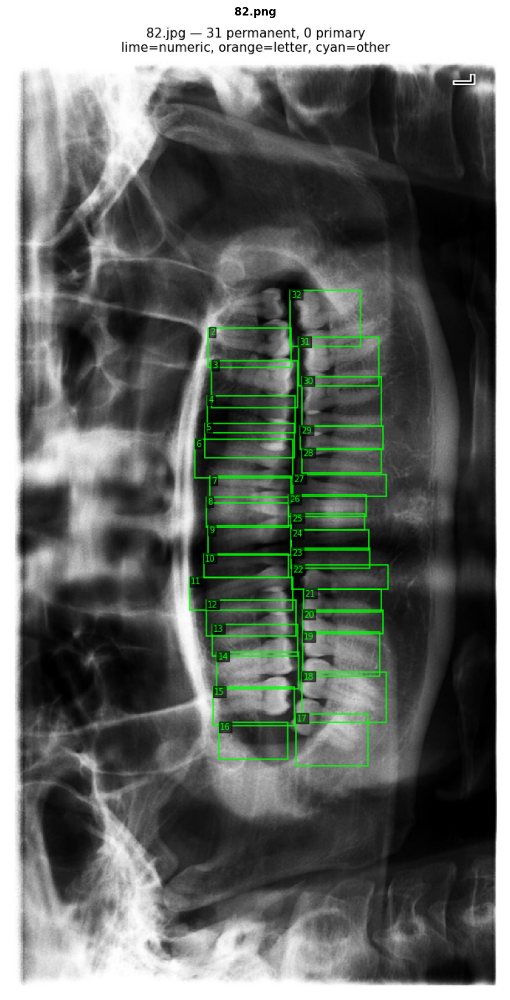

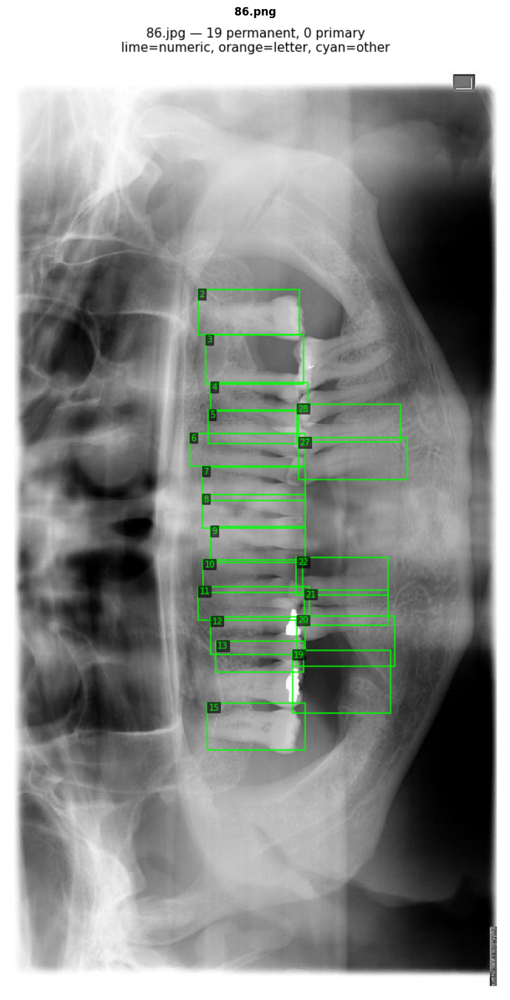

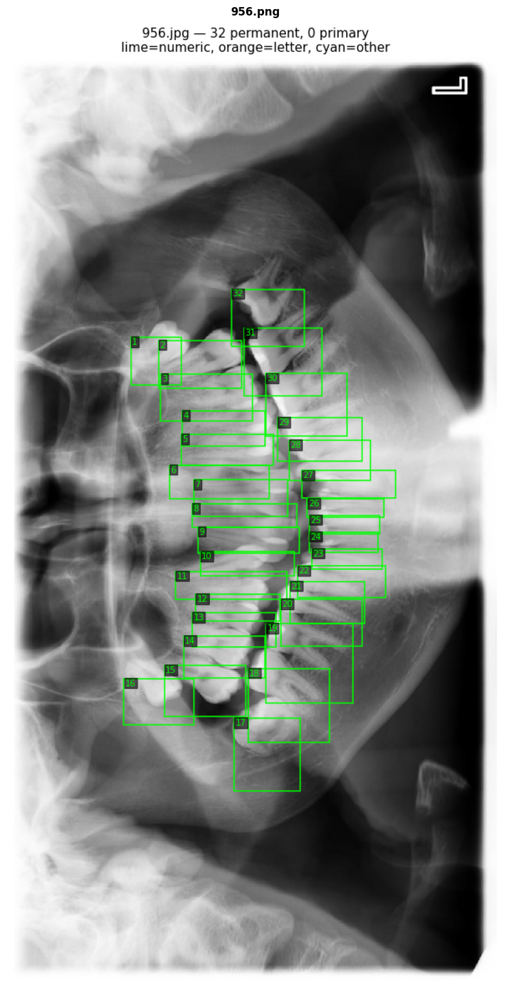

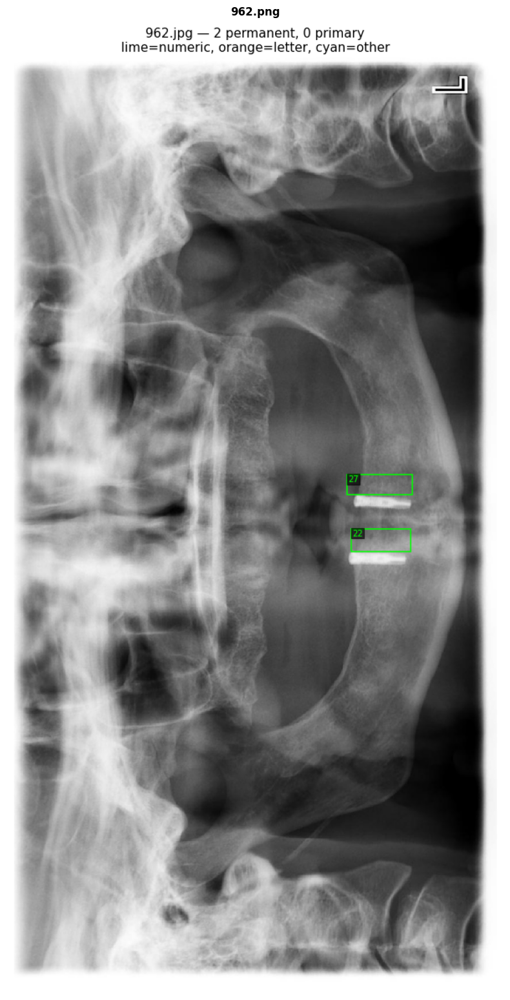

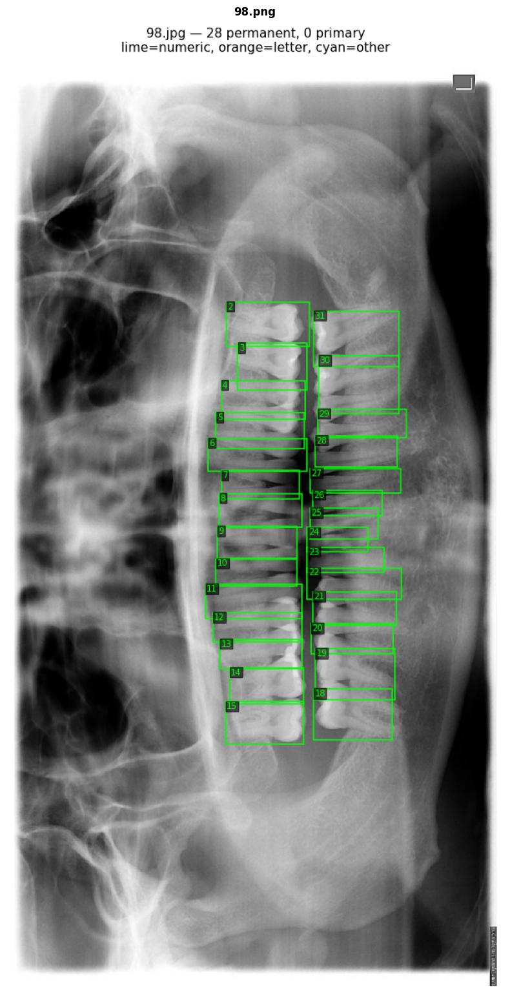


Done – 20 images rendered inline.


In [15]:
import glob, os

sample_dir = OUTPUT_DIR / "samples"
sample_paths = sorted(glob.glob(str(sample_dir / "*.png")))

print(f"Displaying {len(sample_paths)} sample visualizations inline …\n")

for sp in sample_paths:
    img = Image.open(sp)
    w_px, h_px = img.size

    # scale so the figure is ~8 inches wide; keep aspect ratio
    fig_w = 8
    fig_h = fig_w * (h_px / w_px)

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.imshow(img)
    ax.set_title(os.path.basename(sp), fontsize=12, fontweight="bold")
    ax.axis("off")
    plt.tight_layout()
    plt.show()          # renders inline – DO NOT use plt.close() before show
    plt.close(fig)      # free memory after rendering

print(f"\nDone – {len(sample_paths)} images rendered inline.")

## 11. Generate FROZEN split CSV

Image-level 70/15/15 split. Seed = 42. Once generated, this is the permanent reference for all future training.

**If split_v1.csv already exists, it is NOT regenerated.** To force regeneration, delete the file manually.

In [12]:
split_path = OUTPUT_DIR / "split_v1.csv"

def _norm_fname(name: str) -> str:
    # Normalize filenames so `empty_images` from JSON matches filesystem inventory reliably
    # (case + whitespace issues are common).
    return Path(str(name)).name.strip().lower()

def _recompute_is_empty(df: pd.DataFrame) -> pd.Series:
    empty_set = {_norm_fname(f) for f in empty_images}
    return df["filename"].map(lambda f: _norm_fname(f) in empty_set)

if split_path.exists():
    print(f"Split already exists at {split_path}")
    print("NOT regenerating splits. Validating/repairing `is_empty` flag only.")
    df_split = pd.read_csv(split_path)

    if "filename" not in df_split.columns or "split" not in df_split.columns:
        raise ValueError(f"Invalid split file schema: {split_path}")

    # Repair `is_empty` deterministically without changing split assignments.
    df_split["is_empty"] = _recompute_is_empty(df_split)
    df_split.to_csv(split_path, index=False)
else:
    # Use ALL files from inventory (not just those with annotations)
    # Empty images are still part of the inventory but will be naturally
    # skipped during training since they have no YOLO labels.
    all_images = sorted(df_files["filename"].unique())
    
    rng = np.random.RandomState(RANDOM_SEED)
    indices = np.arange(len(all_images))
    rng.shuffle(indices)
    
    n_total = len(indices)
    n_train = int(n_total * SPLIT_RATIOS[0])
    n_val = int(n_total * SPLIT_RATIOS[1])
    
    train_idx = set(indices[:n_train])
    val_idx = set(indices[n_train:n_train + n_val])
    test_idx = set(indices[n_train + n_val:])
    
    split_labels = []
    for i, fname in enumerate(all_images):
        if i in train_idx:
            split_labels.append("train")
        elif i in val_idx:
            split_labels.append("val")
        else:
            split_labels.append("test")
    
    df_split = pd.DataFrame({
        "filename": all_images,
        "split": split_labels,
    })
    df_split["is_empty"] = _recompute_is_empty(df_split)
    df_split.to_csv(split_path, index=False)
    print(f"Split generated and saved to {split_path}")

print(f"\nSplit counts:\n{df_split['split'].value_counts()}")
print("\nEmpty images per split:")
print(df_split.groupby("split")["is_empty"].sum().astype(int))

# Sanity: no overlap
assert len(df_split) == df_split["filename"].nunique(), "Duplicate filenames in split"
print("\nSplit integrity OK.")

Split generated and saved to outputs/eda_tufts/split_v1.csv

Split counts:
split
train    700
test     150
val      150
Name: count, dtype: int64

Empty images per split:
split
test      6
train    21
val       5
Name: is_empty, dtype: int64

Split integrity OK.


## 12. Machine-flagged issues + manual observation template

Writes `issues.md` with auto-detected issues and a section for you to fill in after reviewing `samples/`.

In [13]:
issues = []

if len(df_files) < 990:
    issues.append(f"Image count unexpectedly low: {len(df_files)} (Tufts should be ~1000)")
if len(df_files) > 1010:
    issues.append(f"Image count unexpectedly high: {len(df_files)}")

tiny = df_files[df_files["size_mb"] < 0.05]
if len(tiny) > 0:
    issues.append(f"{len(tiny)} files under 50 KB — possibly corrupt")

if len(empty_images) > 50:
    issues.append(f"{len(empty_images)} images have zero annotations — unusually high")
elif len(empty_images) > 0:
    issues.append(f"{len(empty_images)} images have zero annotations (expected ~32)")

if degenerate_count > 100:
    issues.append(f"{degenerate_count} degenerate boxes — unusually high")

if mixed_dentition > 0:
    issues.append(f"{mixed_dentition} images have primary (letter) tooth annotations — mixed dentition present")

if not has_patient_ids:
    issues.append("No patient IDs — image-level split used (document as limitation in paper)")

issue_lines = [
    "# Data Quality Issues — Tufts EDA Week 1",
    "",
    "## Machine-flagged issues",
    "",
]
if issues:
    issue_lines.extend([f"- {i}" for i in issues])
else:
    issue_lines.append("- None detected")

issue_lines.extend([
    "",
    "## Manual observations (YOU fill these in)",
    "",
    "After reviewing `outputs/eda_tufts/samples/`, note findings below:",
    "",
    "### Box alignment quality",
    "- [ ] Boxes sit correctly on teeth in all 20 samples?",
    "- Observations: ",
    "",
    "### Missing annotations",
    "- Any visible teeth without boxes? Which cases:",
    "- ",
    "",
    "### Non-teeth annotations",
    "- Any boxes on fillings/implants/crowns instead of teeth?",
    "- ",
    "",
    "### Unusual cases",
    "- Edentulous or partial dentition cases:",
    "- ",
    "- Mixed dentition (permanent + primary) cases:",
    "- ",
    "- Impacted, supernumerary, or other rare findings:",
    "- ",
    "",
    "### Decisions",
    "- [ ] Letter titles (primary teeth): keep for training (see Rule 5)",
    "- [ ] Degenerate boxes: dropped (66 total)",
    "- [ ] Empty images: kept in inventory, flagged via `is_empty` column",
    "- [ ] Images with <20 permanent teeth: kept (real clinical variability)",
    "",
])

(OUTPUT_DIR / "issues.md").write_text("\n".join(issue_lines))
print(f"Issues written to {OUTPUT_DIR / 'issues.md'}")
print("\n*** OPEN issues.md AND FILL IN MANUAL OBSERVATIONS AFTER REVIEWING samples/ ***")

Issues written to outputs/eda_tufts/issues.md

*** OPEN issues.md AND FILL IN MANUAL OBSERVATIONS AFTER REVIEWING samples/ ***


## 13. Final report

One-page summary of everything above. Check this into git with the split.

In [14]:
report = [
    "# Tufts EDA Report — Week 1",
    "",
    f"**Random seed:** {RANDOM_SEED}",
    f"**Source directory:** `{RADIOGRAPHS_DIR}`",
    f"**Annotations:** `{BBOX_JSON}`",
    "",
    "## Dataset overview",
    f"- Total rotated images: **{len(df_files)}**",
    f"- Image dimensions (verified): **840 × 1615** (portrait, after 90° CCW rotation)",
    f"- Total annotation entries in JSON: **1000** (one per image)",
    f"- Total annotation boxes (after filtering): **{len(df_ann)}**",
    f"  - Numeric titles (1-32, permanent): {(df_ann['title_type'] == 'numeric').sum()}",
    f"  - Letter titles (A-T, primary): {(df_ann['title_type'] == 'letter').sum()}",
    f"- Unique images with annotations: **{df_ann['image_file'].nunique()}**",
    f"- Empty images (0 annotations): **{len(empty_images)}**",
    f"- Degenerate boxes dropped (w<2 or h<2): **{degenerate_count}**",
    "",
    "## Dentition characteristics",
    f"- Mean permanent teeth per image: **{teeth_per_image_numeric.mean():.1f}**",
    f"- Median permanent teeth per image: **{teeth_per_image_numeric.median():.0f}**",
    f"- Images with <20 permanent teeth: **{len(low_count)}** (partial dentition, kept)",
    f"- Images with any primary teeth: **{mixed_dentition}** (mixed dentition, kept)",
    "",
    "## Patient-level splitting",
    f"- Patient IDs available in filenames: **{has_patient_ids}**",
    f"- Split strategy: **image-level 70/15/15 random split**",
    f"- **Limitation**: Tufts provides no patient identifiers; we assume each image is an independent patient.",
    "",
    "## Split counts",
    "| Split | Total images | Empty images |",
    "|---|---|---|",
]
for s in ["train", "val", "test"]:
    total = (df_split["split"] == s).sum()
    empty = ((df_split["split"] == s) & df_split["is_empty"]).sum()
    report.append(f"| {s} | {total} | {empty} |")

report.extend([
    "",
    "## Key decisions (locked)",
    "1. **Rotation**: 90° CCW verified correct via multi-image alignment check",
    "2. **Title interpretation**: Tufts 1-32 are custom sequential numbering, NOT FDI",
    "   - FDI mapping deferred to teammate's Stage 2 work (requires visual inspection)",
    "3. **Letter titles (primary teeth)**: kept for single-class tooth detection",
    "4. **Degenerate boxes**: dropped (annotation errors)",
    "5. **Empty images**: flagged but kept in inventory",
    "",
    "## Outputs generated",
    "- `inventory.csv` — file inventory",
    "- `annotations.csv` — per-annotation records",
    "- `image_properties.csv` — sampled image dimensions",
    "- `empty_images.txt` — list of 0-annotation images",
    "- `split_v1.csv` — frozen 70/15/15 split",
    "- `distributions.png`, `title_coverage.png` — plots",
    "- `samples/` — 20 visualizations",
    "- `issues.md` — flagged issues + manual observation template",
    "",
    "## Next steps (Week 1 remaining)",
    "1. **Review `samples/` manually** — verify box-tooth alignment, note anomalies in `issues.md`",
    "2. **Fill in manual observations** in `issues.md`",
    "3. **Copy `split_v1.csv` to `data/splits/tufts_split_v1.csv` and commit to git**",
    "4. **Tag the commit**: `git tag tufts-split-v1`",
    "5. **EDA of `teeth_mask/` folder** (separate notebook) — needed for YOLOv11l-seg masks",
    "",
    "## Next steps (Week 2)",
    "1. Convert Tufts annotations to YOLO format (single class, boxes + masks)",
    "2. Build preprocessing module (CLAHE, normalize, resize to 1024)",
    "3. Set up YOLOv11l-seg training on H100",
    "4. First training run + baseline mAP",
])

(OUTPUT_DIR / "report.md").write_text("\n".join(report))
print(f"Report written to {OUTPUT_DIR / 'report.md'}")
print("\n" + "="*70)
print("Week 1 EDA notebook complete.")
print("="*70)
print("\nNext actions:")
print(f"  1. Open {OUTPUT_DIR / 'samples'}/ and review all 20 visualizations")
print(f"  2. Fill in manual observations in {OUTPUT_DIR / 'issues.md'}")
print(f"  3. Copy split_v1.csv to data/splits/ and commit to git")
print(f"  4. When ready, start Week 1 Day 4: teeth_mask/ EDA")

Report written to outputs/eda_tufts/report.md

Week 1 EDA notebook complete.

Next actions:
  1. Open outputs/eda_tufts/samples/ and review all 20 visualizations
  2. Fill in manual observations in outputs/eda_tufts/issues.md
  3. Copy split_v1.csv to data/splits/ and commit to git
  4. When ready, start Week 1 Day 4: teeth_mask/ EDA


In [16]:
import pandas as pd

df_ann = pd.read_csv("outputs/eda_tufts/annotations.csv")
df_ann["aspect"] = df_ann["bbox_w"] / df_ann["bbox_h"]

left = df_ann[df_ann["tufts_title"].isin([str(i) for i in range(1, 17)])]
right = df_ann[df_ann["tufts_title"].isin([str(i) for i in range(17, 33)])]

print("LEFT column (titles 1-16):")
print(f"  N = {len(left)}")
print(f"  Aspect ratio (w/h): median = {left['aspect'].median():.2f}, mean = {left['aspect'].mean():.2f}")
print(f"  Width  (px): median = {left['bbox_w'].median():.0f}, mean = {left['bbox_w'].mean():.1f}")
print(f"  Height (px): median = {left['bbox_h'].median():.0f}, mean = {left['bbox_h'].mean():.1f}")
print(f"  Area   (px²): median = {left['bbox_area'].median():.0f}")

print(f"\nRIGHT column (titles 17-32):")
print(f"  N = {len(right)}")
print(f"  Aspect ratio (w/h): median = {right['aspect'].median():.2f}, mean = {right['aspect'].mean():.2f}")
print(f"  Width  (px): median = {right['bbox_w'].median():.0f}, mean = {right['bbox_w'].mean():.1f}")
print(f"  Height (px): median = {right['bbox_h'].median():.0f}, mean = {right['bbox_h'].mean():.1f}")
print(f"  Area   (px²): median = {right['bbox_area'].median():.0f}")

print(f"\nDIFFERENCES (right vs left):")
print(f"  Aspect ratio: {right['aspect'].median() - left['aspect'].median():+.2f}")
print(f"  Width:  {100*(right['bbox_w'].median() - left['bbox_w'].median())/left['bbox_w'].median():+.1f}%")
print(f"  Height: {100*(right['bbox_h'].median() - left['bbox_h'].median())/left['bbox_h'].median():+.1f}%")
print(f"  Area:   {100*(right['bbox_area'].median() - left['bbox_area'].median())/left['bbox_area'].median():+.1f}%")

# Count extreme "flat bar" boxes (aspect > 3.0 = width 3x height)
flat_left = (left["aspect"] > 3.0).sum()
flat_right = (right["aspect"] > 3.0).sum()
print(f"\nExtreme flat boxes (aspect > 3.0):")
print(f"  Left:  {flat_left}/{len(left)} = {100*flat_left/len(left):.1f}%")
print(f"  Right: {flat_right}/{len(right)} = {100*flat_right/len(right):.1f}%")

LEFT column (titles 1-16):
  N = 12440
  Aspect ratio (w/h): median = 2.74, mean = 2.73
  Width  (px): median = 156, mean = 153.4
  Height (px): median = 57, mean = 60.2
  Area   (px²): median = 8960

RIGHT column (titles 17-32):
  N = 12761
  Aspect ratio (w/h): median = 2.64, mean = 2.59
  Width  (px): median = 143, mean = 140.7
  Height (px): median = 55, mean = 65.8
  Area   (px²): median = 8100

DIFFERENCES (right vs left):
  Aspect ratio: -0.09
  Width:  -8.3%
  Height: -3.5%
  Area:   -9.6%

Extreme flat boxes (aspect > 3.0):
  Left:  4962/12440 = 39.9%
  Right: 4916/12761 = 38.5%


In [18]:
from pathlib import Path
from PIL import Image
import numpy as np

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")
mask_dir = TUFTS_ROOT / "Segmentation" / "teeth_mask"

files = sorted(mask_dir.iterdir())
print(f"Items in teeth_mask/: {len(files)}")
print(f"First 5: {[f.name for f in files[:5]]}")
print(f"Is subfolder? {files[0].is_dir()}")

# If files, load one
if files[0].is_file():
    sample = Image.open(files[0])
    arr = np.array(sample)
    print(f"\nFirst mask: {files[0].name}")
    print(f"Dimensions: {sample.width} x {sample.height}")
    print(f"Mode: {sample.mode}")
    print(f"Shape: {arr.shape}, dtype: {arr.dtype}")
    print(f"Unique values: {np.unique(arr)[:50]}")

Items in teeth_mask/: 1000
First 5: ['1.jpg', '100.jpg', '1000.jpg', '1001.jpg', '1002.jpg']
Is subfolder? False

First mask: 1.jpg
Dimensions: 1615 x 840
Mode: RGB
Shape: (840, 1615, 3), dtype: uint8
Unique values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]


In [19]:
from PIL import Image
import numpy as np
from pathlib import Path

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")
mask = Image.open(TUFTS_ROOT / "Segmentation" / "teeth_mask" / "1.jpg")
arr = np.array(mask)

print(f"Shape: {arr.shape}")
print(f"Channel 0 unique values: {np.unique(arr[:,:,0])[:30]}")
print(f"Channel 1 unique values: {np.unique(arr[:,:,1])[:30]}")
print(f"Channel 2 unique values: {np.unique(arr[:,:,2])[:30]}")

# Are all 3 channels identical?
r_eq_g = np.array_equal(arr[:,:,0], arr[:,:,1])
g_eq_b = np.array_equal(arr[:,:,1], arr[:,:,2])
print(f"\nR == G: {r_eq_g}")
print(f"G == B: {g_eq_b}")

# Sanity check — count pixels per tooth label
labels, counts = np.unique(arr[:,:,0], return_counts=True)
print(f"\nLabel → pixel count:")
for label, count in zip(labels, counts):
    if label > 0:
        print(f"  Tooth {label}: {count} pixels")

Shape: (840, 1615, 3)
Channel 0 unique values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]
Channel 1 unique values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]
Channel 2 unique values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29]

R == G: True
G == B: True

Label → pixel count:
  Tooth 1: 2009 pixels
  Tooth 2: 1113 pixels
  Tooth 3: 1041 pixels
  Tooth 4: 689 pixels
  Tooth 5: 578 pixels
  Tooth 6: 435 pixels
  Tooth 7: 429 pixels
  Tooth 8: 310 pixels
  Tooth 9: 269 pixels
  Tooth 10: 221 pixels
  Tooth 11: 181 pixels
  Tooth 12: 150 pixels
  Tooth 13: 153 pixels
  Tooth 14: 86 pixels
  Tooth 15: 71 pixels
  Tooth 16: 73 pixels
  Tooth 17: 50 pixels
  Tooth 18: 38 pixels
  Tooth 19: 38 pixels
  Tooth 20: 37 pixels
  Tooth 21: 26 pixels
  Tooth 22: 29 pixels
  Tooth 23: 31 pixels
  Tooth 24: 31 pixels
  Tooth 25: 21 pixels
  Tooth 26: 22 pix

In [20]:
from PIL import Image
import numpy as np
from pathlib import Path

TUFTS_ROOT = Path("/Users/chennupatigunadeep/Downloads/Capstone/DataSets")
mask = Image.open(TUFTS_ROOT / "Segmentation" / "teeth_mask" / "1.jpg")
arr = np.array(mask)[:, :, 0]

# Histogram of pixel values
unique, counts = np.unique(arr, return_counts=True)

print("Top 50 most common pixel values:")
sorted_idx = np.argsort(counts)[::-1][:50]
for idx in sorted_idx:
    print(f"  Value {unique[idx]}: {counts[idx]} pixels")

print(f"\nTotal pixels: {arr.size}")
print(f"Pixels at exactly 0: {(arr == 0).sum()}")
print(f"Pixels at exactly 255: {(arr == 255).sum()}")
print(f"Pixels with value 1-32: {((arr >= 1) & (arr <= 32)).sum()}")
print(f"Pixels with value 33-254: {((arr >= 33) & (arr <= 254)).sum()}")

Top 50 most common pixel values:
  Value 0: 1298310 pixels
  Value 255: 38563 pixels
  Value 254: 2248 pixels
  Value 1: 2009 pixels
  Value 253: 1399 pixels
  Value 2: 1113 pixels
  Value 3: 1041 pixels
  Value 252: 916 pixels
  Value 251: 710 pixels
  Value 4: 689 pixels
  Value 5: 578 pixels
  Value 250: 451 pixels
  Value 6: 435 pixels
  Value 7: 429 pixels
  Value 249: 384 pixels
  Value 248: 327 pixels
  Value 8: 310 pixels
  Value 247: 295 pixels
  Value 246: 276 pixels
  Value 9: 269 pixels
  Value 10: 221 pixels
  Value 245: 189 pixels
  Value 11: 181 pixels
  Value 244: 162 pixels
  Value 13: 153 pixels
  Value 12: 150 pixels
  Value 243: 141 pixels
  Value 242: 113 pixels
  Value 241: 98 pixels
  Value 14: 86 pixels
  Value 71: 77 pixels
  Value 204: 76 pixels
  Value 240: 76 pixels
  Value 16: 73 pixels
  Value 239: 73 pixels
  Value 15: 71 pixels
  Value 238: 59 pixels
  Value 200: 57 pixels
  Value 51: 55 pixels
  Value 145: 55 pixels
  Value 235: 52 pixels
  Value 17: 50